In [1]:
import sys
sys.path.append('../')
from utils import plotting_utils
import pickle
import jax.numpy as jnp

# Constant BC

In [2]:
# input_folder = '../output/Simulations_Paper/ERA5_Sweden/simulations/simulation_'
input_folder = '../output/Simulations_Paper/Constant/runoff/'

In [ ]:
constant_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "permaFoam_omega10": "permaFoam_omega10.pkl",
    "permaFoam_omega50": "permaFoam_omega50.pkl",
    "cap": "cap.pkl",
}

constant_dbs = {}
for parametrization, filename in constant_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        constant_dbs[parametrization] = pickle.load(pickle_file)


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


In [ ]:
for idx,parametrization in enumerate(constant_dbs):
    print(parametrization)
    theta_i_total = constant_dbs[parametrization]["theta_i_total"]
    max_theta_i = 0
    for i in range(len(theta_i_total)):
        if jnp.max(theta_i_total[i])>max_theta_i:
            id_max = i
            max_theta_i = jnp.max(theta_i_total[i])
    print(id_max/12, max_theta_i)

drying
58.75 0.17851734
drying_omega10
79.08333333333333 0.16572271
permaFoam_omega10
81.75 0.17256686
permaFoam_omega50
79.5 0.16138309
cap
54.25 0.38499352


/home/anne/anaconda3/envs/cryo_AD/lib/python3.14/site-packages/matplotlib/patches.py:3582: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


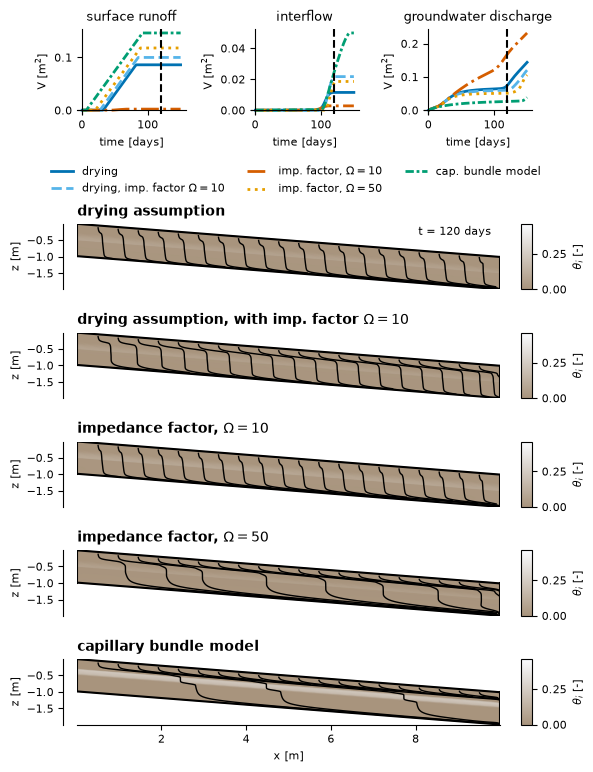

In [ ]:
index = 12*120
cm = 1/2.54  # centimeters in inches
fig, axes = plotting_utils.plot_streamlines_grid(constant_dbs, index, slope=-0.1,figsize=(15*cm,19.41*cm),cum=True)
fig.savefig(f"../figures/Simulations_Paper/Constant/constant_{index//12}d_streamlines_cum.png", dpi=600)

## Temperature distribution     

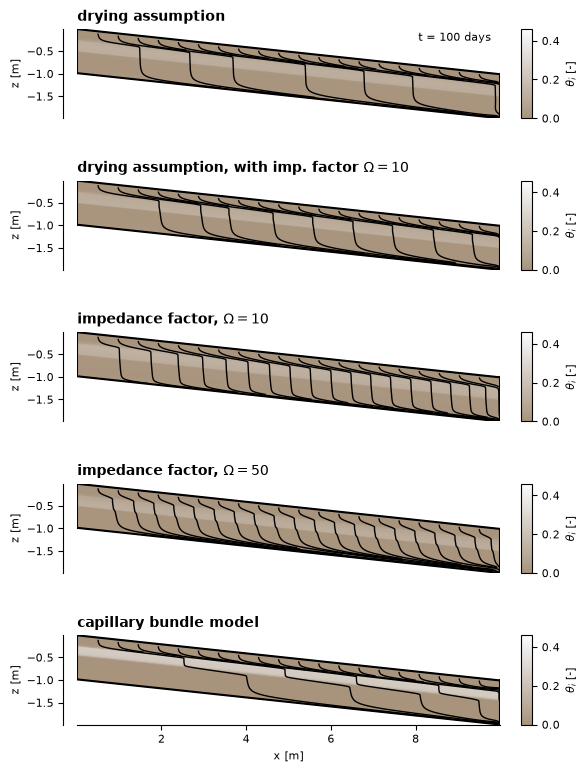

In [ ]:
index = 100*12
fig, axes = plotting_utils.plot_streamlines_grid(constant_dbs, index, slope=-0.1,figsize=(15*cm,19.41*cm),cum=False)

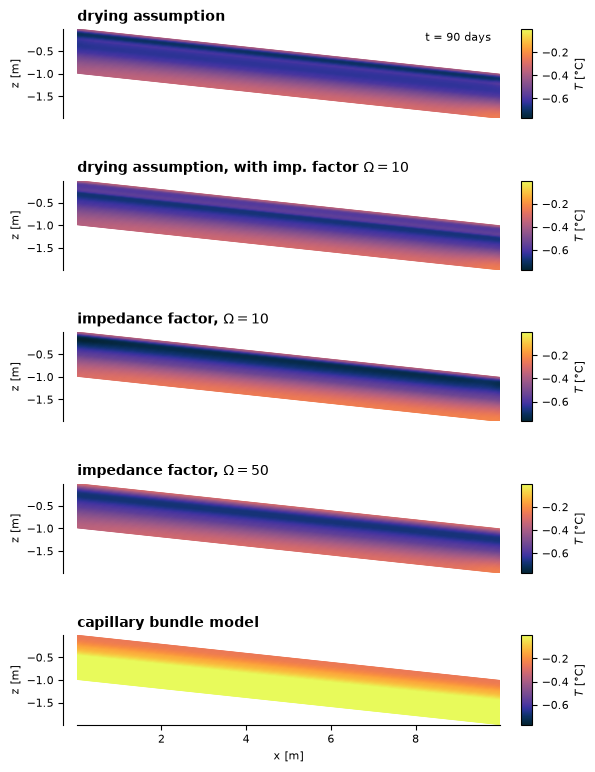

In [ ]:
fig, axes = plotting_utils.plot_T_grid(constant_dbs, index, field_key="T_total",figsize=(15*cm,19.41*cm))
fig.savefig(f"../figures/Simulations_Paper/Constant/constant_{index//12}d_T.png", dpi=600)

## Forcing comparison: ERA5 vs. constant-BC ramp

Shows the real ERA5-Land forcing used for the `simulation` segment (post-spinup, i.e. what the constant-BC run stands in for) next to the smoothed tanh cooling/warming ramp used in the constant-BC runoff test. Axes are independent (not shared): the ERA5 recharge peaks and temperature range are 2-3 orders of magnitude larger/wider than the idealized ramp, so a shared scale would flatten the ramp panel to an invisible line. The point of the figure is to show the *character* (spiky/eventful vs. smooth/idealized) of each forcing, not to overlay them at matching magnitude.

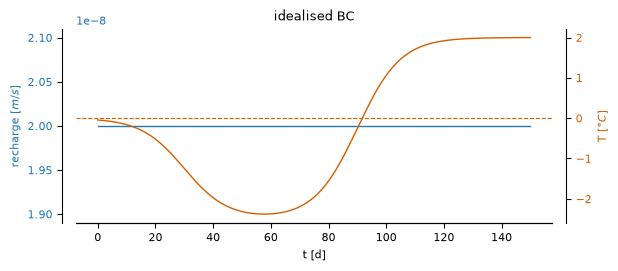

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- constant-BC tanh ramp forcing (same formula as Constant_*.ipynb cell 04c2d77c) ---
T_cold, T_warm = -2.5, 2.0
t1, w1 = 30.0, 15.0   # cooling transition centered day 30, ~30 d wide
t2, w2 = 90.0, 15.0   # warming transition centered day 90, ~30 d wide
t_const = np.linspace(0, 150, 1000)
s_cool = 0.5 * (1 + np.tanh((t_const - t1) / w1))
s_warm = 0.5 * (1 + np.tanh((t_const - t2) / w2))
T_const = 0.0 + (T_cold - 0.0) * s_cool + (T_warm - T_cold) * s_warm
q_const = 2e-8 * np.ones_like(t_const)

cm = 1/2.54  # centimeters in inches
fig, ax = plt.subplots(1, figsize=(16*cm, 7*cm))

ax.set_title("idealised BC")
ax.plot(t_const, q_const, color='tab:blue', linewidth=1)
ax.set_ylabel('recharge $[m/s]$', color='tab:blue')
ax.tick_params(axis='y', labelcolor='tab:blue')
ax.set_xlabel('t [d]')
ax.spines[['top','right']].set_visible(False)

ax_cp = ax.twinx()
ax_cp.plot(t_const, T_const, color="#D55E00", linewidth=1)
ax_cp.set_ylabel('T $[°C]$', color="#D55E00")
ax_cp.tick_params(axis='y', labelcolor="#D55E00")
ax_cp.axhline(0, color="#D55E00", linestyle='--', linewidth=0.8)
ax_cp.spines[['top','left']].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax_cp.spines['right'].set_position(('outward', 10))

fig.tight_layout()
fig.savefig("../figures/Simulations_Paper/Constant/forcing_comparison.png", dpi=600)

# ERA5-Land BC Simulation

In [ ]:
input_folder = '../output/Simulations_Paper/ERA5_Sweden/simulations/tl1/simulation_'
# input_folder = '../output/Simulations_Paper/Constant/Interpolation/'

In [ ]:
era5_files = {
    "drying": "drying.pkl",
    "drying_omega10": "drying_omega10.pkl",
    "permaFoam_omega10": "permaFoam_omega10.pkl",
    "permaFoam_omega50": "permaFoam_omega50.pkl",
    "cap": "cap.pkl",
}

era5_dbs = {}
for parametrization, filename in era5_files.items():
    with open(input_folder + filename, 'rb') as pickle_file:
        era5_dbs[parametrization] = pickle.load(pickle_file)


In [ ]:
for idx,parametrization in enumerate(era5_dbs):
    print(parametrization)
    theta_i_total = era5_dbs[parametrization]["theta_i_total"]
    max_theta_i = 0
    for i in range(len(theta_i_total)):
        if jnp.max(theta_i_total[i])>max_theta_i:
            id_max = i
            max_theta_i = jnp.max(theta_i_total[i])
    print(id_max/12, max_theta_i)

drying
58.75 0.17851734
drying_omega10
79.08333333333333 0.16572271
permaFoam_omega10
81.75 0.17256686
permaFoam_omega50
79.5 0.16138309
cap
54.25 0.38499352


## Cumulative partitioning comparison across parametrizations

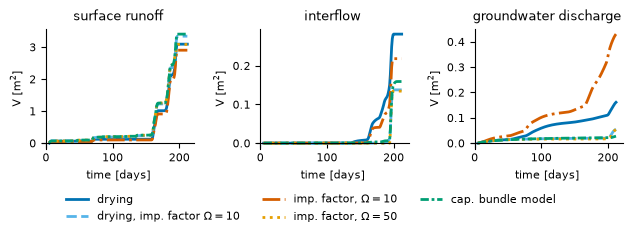

In [ ]:
fig, axes = plotting_utils.plot_cumulative_partitioning_grid(era5_dbs, relative=False)
fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/tl1/sim_cum.png", dpi=600)

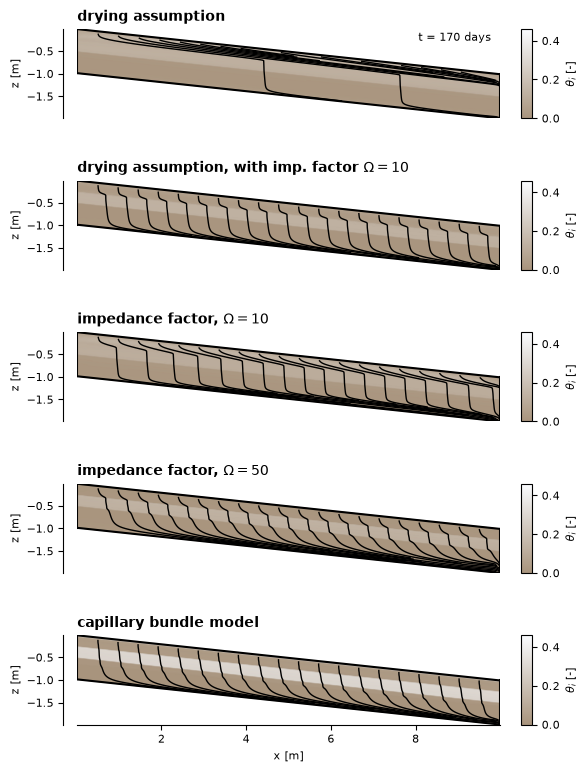

In [ ]:
index = 170
fig, axes = plotting_utils.plot_streamlines_grid(era5_dbs, index, slope=-0.1,figsize=(15*cm,19.41*cm),cum=False)
fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/tl1/sim_{index}.png",dpi=600)

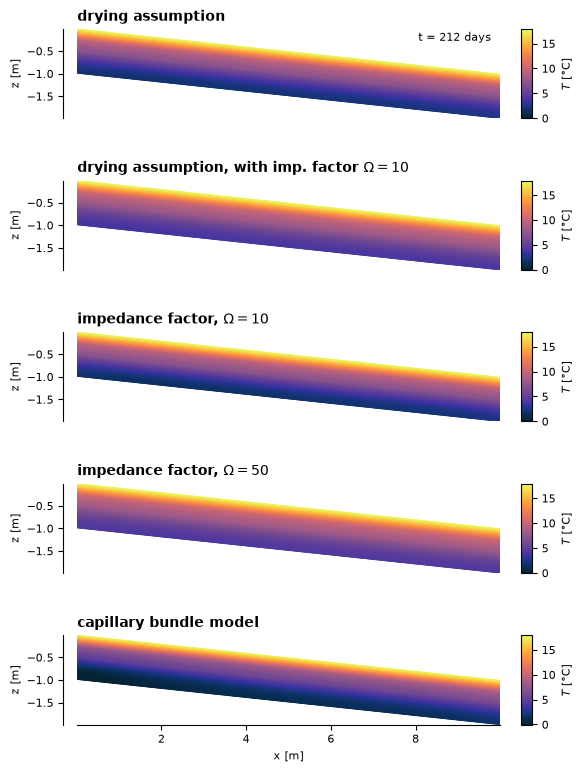

In [ ]:
index = -1
fig, axes = plotting_utils.plot_T_grid(era5_dbs, index, field_key="T_total",figsize=(15*cm,19.41*cm))
fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/tl1/sim_{index}d_T.png",dpi=600)

# Mechanism: capillary barrier vs. ice lens

In [ ]:
# for parametrization, db in era5_dbs.items():
#     fig, axes = plotting_utils.plot_Ku(db, parametrization, [7, 71, 165],
#                                        interp_folder="../input/interpolation/",
#                                        suptitle=plotting_utils.parametrization_label(parametrization))
#     # fig.savefig(f"../figures/Simulations_Paper/ERA5_Sweden/Ku_{parametrization}.png", dpi=300)
